# [GSE49828](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE49828)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-12-07
> - Modified: 2024-12-18

# 1. Experimental Design

> 	The DNA methylation landscape of human early embryos.
> - Guo, H., Zhu, P., Yan, L. et al. The DNA methylation landscape of human early embryos. Nature 511, 606–610 (2014). https://doi.org/10.1038/nature13544.
> - RRBS
> - Illumina HiSeq2000/HiSeq2500, PE100

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/rrbs_Hs_Embryos_Diff_GSE49828/00_geo/RRBS"

In [3]:
suppressPackageStartupMessages(library(BSgenome.Hsapiens.UCSC.hg19))
genome <- BSgenome.Hsapiens.UCSC.hg19

suppressPackageStartupMessages(library(TxDb.Hsapiens.UCSC.hg19.knownGene))
txdb <- TxDb.Hsapiens.UCSC.hg19.knownGene

# 2. Import Data

## 1). Import Methylation Calling File

In [4]:
# Load Bismark coverage file as GRanges
load_methylation_calling_bed <- function(
    file, cov = 5, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE) {

    gr <- data.table::fread(
        file, header = FALSE, sep = "\t", comment.char = "#",
        col.names = c(
            "chr", "start", "ref", "strand", "coverage", 
            "numCs", "numTs", "meth", "context", "type")) |>
        dplyr::filter(coverage >= 5) |>
        dplyr::filter(type == "CpG") |>
        mutate(end = start) |>
        GRanges()

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    return(gr)
}

In [5]:
file_pattern <- "(.*)\\.methylation_calling\\.bed\\.txt\\.gz$"

cov_files <- list.files(data_dir, pattern = file_pattern, full.names = TRUE) |>
    set_names(~ sub(file_pattern, "\\1", basename(.x)))

length(cov_files)

[1] 32

In [6]:
stage_levels <- c(
    "Sperm", "MII-Oocyte", "1st-PB", "2nd-PB", "Zygote",
    "2-cell", "4-cell", "8-cell", "Morula", "ICM", "TE",
    "Postimplantation-embryo")

coldata <- tibble(sample = names(cov_files)) |>
    separate(
        sample, into = c("Stage", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Stage = factor(Stage, levels = stage_levels),
        Replicate = factor(Replicate)) |>
    arrange(Stage, Replicate) |>
    column_to_rownames("sample")

head(coldata)

,Stage,Replicate
,<fct>,<fct>
Sperm_rep1,Sperm,rep1
Sperm_rep2,Sperm,rep2
Sperm_rep3,Sperm,rep3
Sperm_rep4,Sperm,rep4
MII-Oocyte_rep1,MII-Oocyte,rep1
MII-Oocyte_rep2,MII-Oocyte,rep2


In [7]:
meth_list <- lapply(
    cov_files, cov = 5, load_methylation_calling_bed, dropSex = FALSE)
meth_list <- meth_list[rownames(coldata)]

meth_list[1]

$Sperm_rep1
GRanges object with 2504106 ranges and 7 metadata columns:
            seqnames    ranges strand |         ref  coverage     numCs
               <Rle> <IRanges>  <Rle> | <character> <integer> <integer>
        [1]     chr7     31442      - |           G         8         0
        [2]     chr7     31468      - |           G         8         0
        [3]     chr7     31514      - |           g        11         0
        [4]     chr7     31542      - |           g        12         0
        [5]     chr7     31547      - |           g        12         0
        ...      ...       ...    ... .         ...       ...       ...
  [2504102]     chr5 180869702      + |           c         5         1
  [2504103]     chr5 180869708      + |           c         6         2
  [2504104]     chr5 180869730      + |           c         6         1
  [2504105]     chr5 180869732      + |           c         5         1
  [2504106]     chr5 180869738      + |           c         5    

# 3. Evaluate Library Quality

# 4. Global Methylation

## 1). Standard Plot

In [8]:
plot_df <- data.frame(
    sample = names(meth_list),
    number = sapply(meth_list, length),
    mean = sapply(meth_list, \(gr) mean(mcols(gr)$meth))) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(mean = mean * 100) |>
    column_to_rownames("sample")

head(plot_df)

,number,mean,Stage,Replicate
,<int>,<dbl>,<fct>,<fct>
Sperm_rep1,2504106,46.78736,Sperm,rep1
Sperm_rep2,3296960,48.39290,Sperm,rep2
Sperm_rep3,3696440,47.68035,Sperm,rep3
Sperm_rep4,3958997,47.14338,Sperm,rep4
MII-Oocyte_rep1,2030912,40.97650,MII-Oocyte,rep1
MII-Oocyte_rep2,1937662,38.35217,MII-Oocyte,rep2


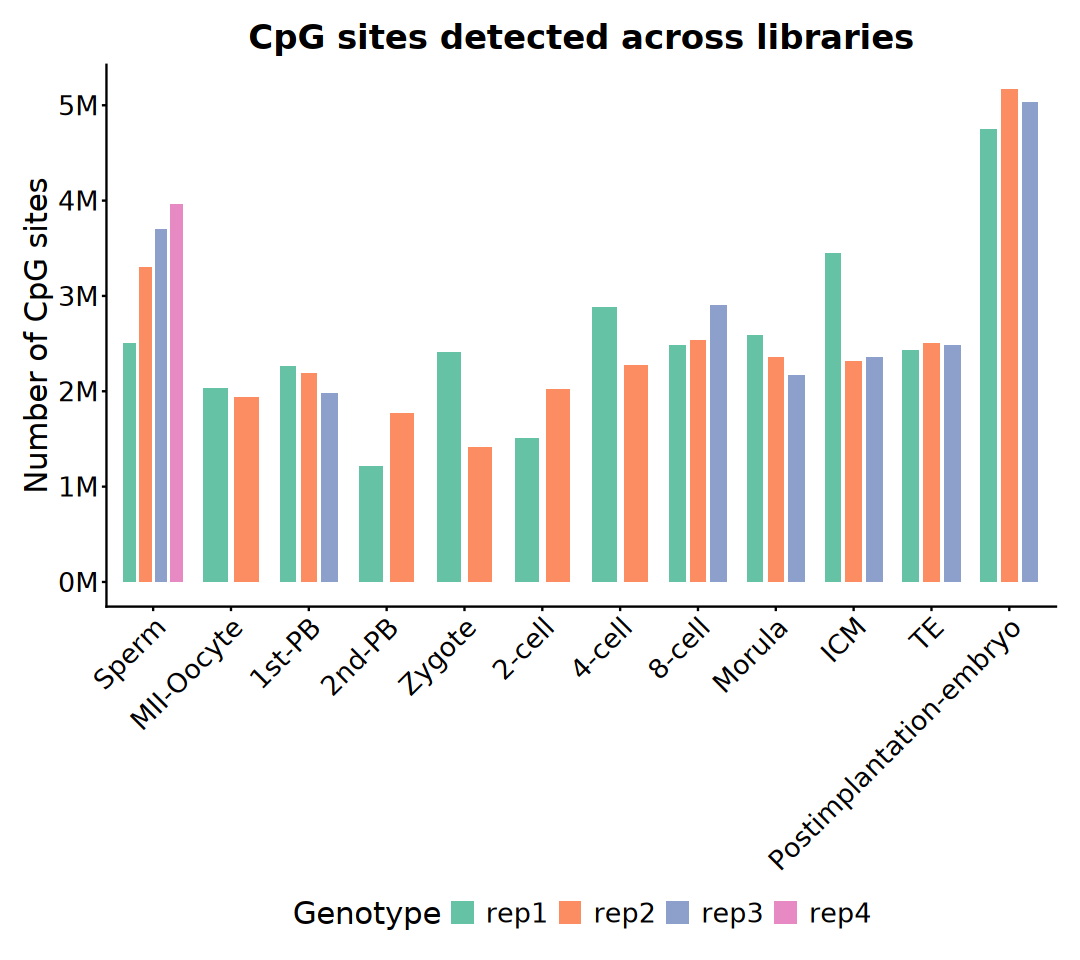

In [9]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = Stage, y = number, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG sites detected across libraries", 
        x = NULL, y = "Number of CpG sites", 
        fill = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

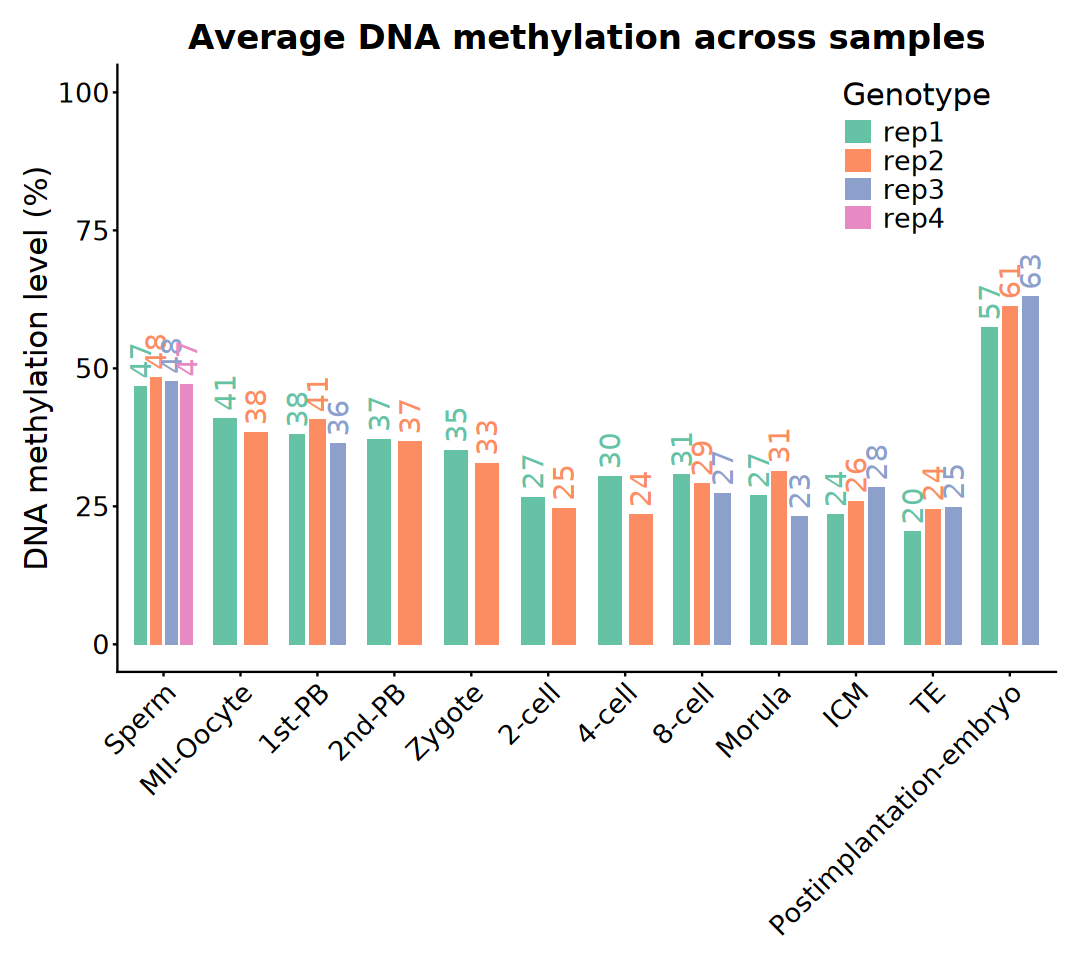

In [10]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = Stage, y = mean, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    geom_text(
        aes(color = Replicate, label = sprintf("%.0f", round(mean, 2))),
        position = position_dodge(width = 0.8),
        angle = 90, vjust = 0.5, hjust = -0.2, size = 6) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Average DNA methylation across samples",
        x = NULL, y = "DNA methylation level (%)", 
        color = "Genotype", fill = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "inside",
        legend.position.inside = c(0.85, 0.85),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

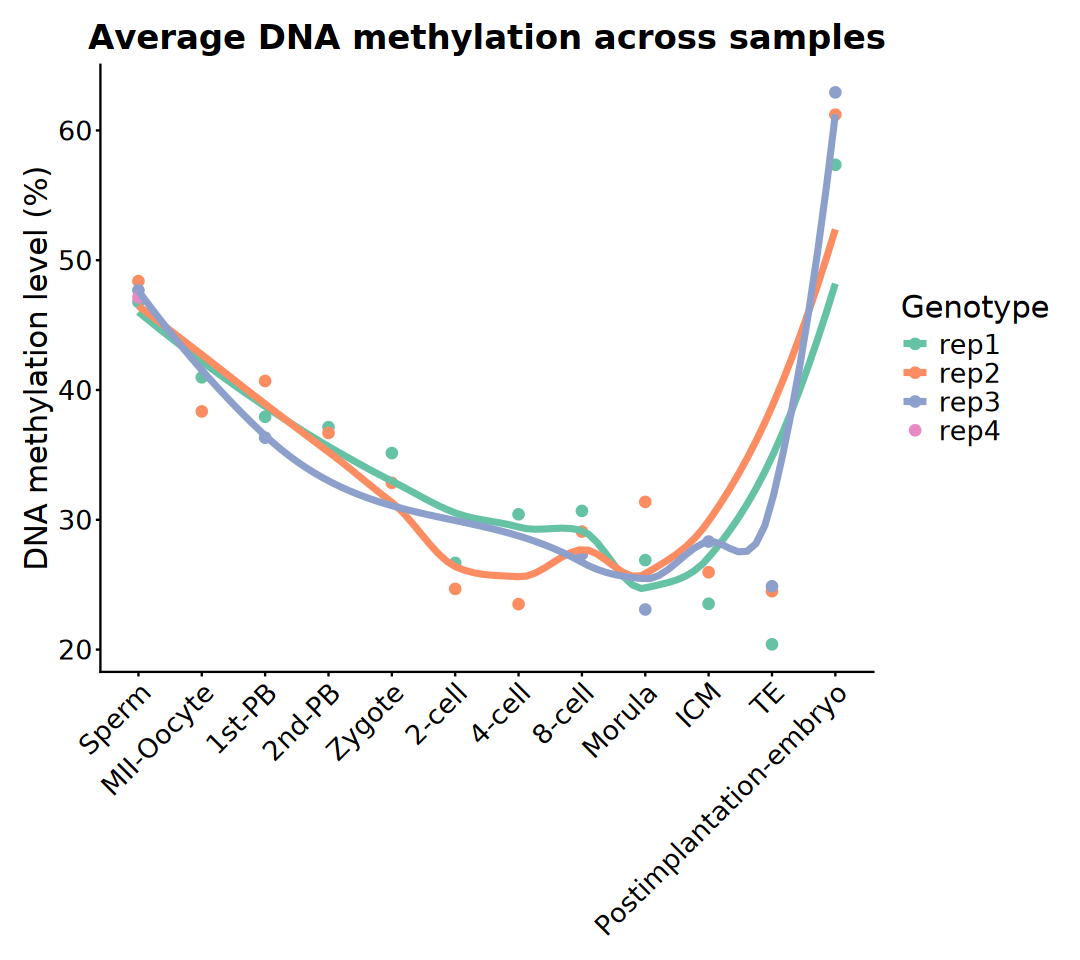

In [11]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = Stage, y = mean, group = Replicate)) +
    geom_point(aes(color = Replicate), size = 2.5) +
    geom_smooth(
        aes(color = Replicate), formula = 'y ~ x', method = 'loess', 
        se = FALSE, linewidth = 1.5) +
    scale_color_brewer(palette = "Set2") +
    labs(
        title = "Average DNA methylation across samples",
        x = NULL, y = "DNA methylation level (%)", 
        color = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        # legend.position = "inside",
        # legend.position.inside = c(0.85, 0.20),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

## 2). Boxplot

In [12]:
plot_df <- map_dfr(meth_list, ~ tibble(
    meth = mcols(.x)$meth), .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

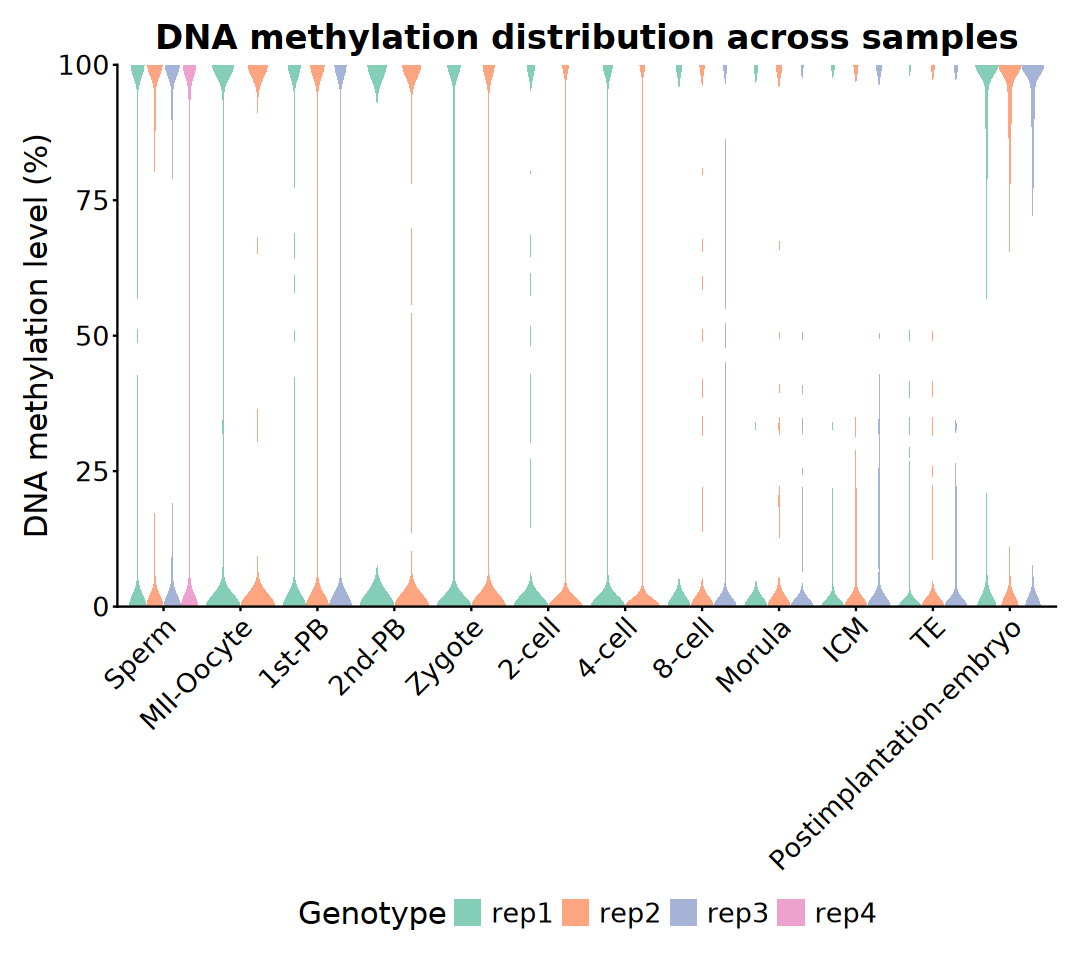

In [13]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = Stage, y = meth * 100, fill = Replicate)) +
    geom_violin(trim = TRUE, scale = "width", color = NA, alpha = 0.8) +
    scale_y_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "DNA methylation distribution across samples",
        x = NULL, y = "DNA methylation level (%)", 
        fill = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

## 3). Metagene Profile

In [14]:
GENES <- genes(txdb)
PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

  24 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [15]:
CGI <- read.table(
    "~/reference/Homo_sapiens/hg19/ucsc/cpgIslandExt.txt", 
    header = FALSE, sep = "\t", col.names = c(
        "bin", "chr", "start", "end", "names", "length", 
        "cpgNum", "gcNum", "perCpg", "perGc", "obsExp")) |>
    dplyr::filter(length > 300) |>
    GRanges() |>
    keepStandardChromosomes(pruning.mode = "coarse")

In [16]:
PROMOTERS$CGI_status <- ifelse(
    overlapsAny(PROMOTERS, CGI), "CGI", "non_CGI") |> 
    factor(levels = c("CGI", "non_CGI"))
table(PROMOTERS$CGI_status)

CGI$Promoter_status <- ifelse(
    overlapsAny(CGI, PROMOTERS), "Promoter", "non_Promoter") |> 
    factor(levels = c("Promoter", "non_Promoter"))
table(CGI$Promoter_status)


    CGI non_CGI 
  14804   13818 


    Promoter non_Promoter 
       11851         9865 

### a). Genes

In [17]:
# ~ 20 min
gene_mat_List <- lapply(
    meth_list, normalizeToMatrix, GENES, value_column = "meth", 
    extend = 2000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.4, background = NA, smooth = FALSE)

In [18]:
position_index <- c(
    paste0("u", seq_len(40)), 
    paste0("t", seq_len(53)), 
    paste0("d", seq_len(40))
)

plot_df <- gene_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(
        pos = factor(pos, levels = position_index), 
        sample = factor(sample, levels = names(meth_list)))

head(plot_df)

sample,pos,meth,Stage,Replicate
<fct>,<fct>,<dbl>,<fct>,<fct>
Sperm_rep1,u1,0.4793196,Sperm,rep1
Sperm_rep1,u2,0.4600459,Sperm,rep1
Sperm_rep1,u3,0.4667141,Sperm,rep1
Sperm_rep1,u4,0.4578485,Sperm,rep1
Sperm_rep1,u5,0.4469988,Sperm,rep1
Sperm_rep1,u6,0.4337958,Sperm,rep1


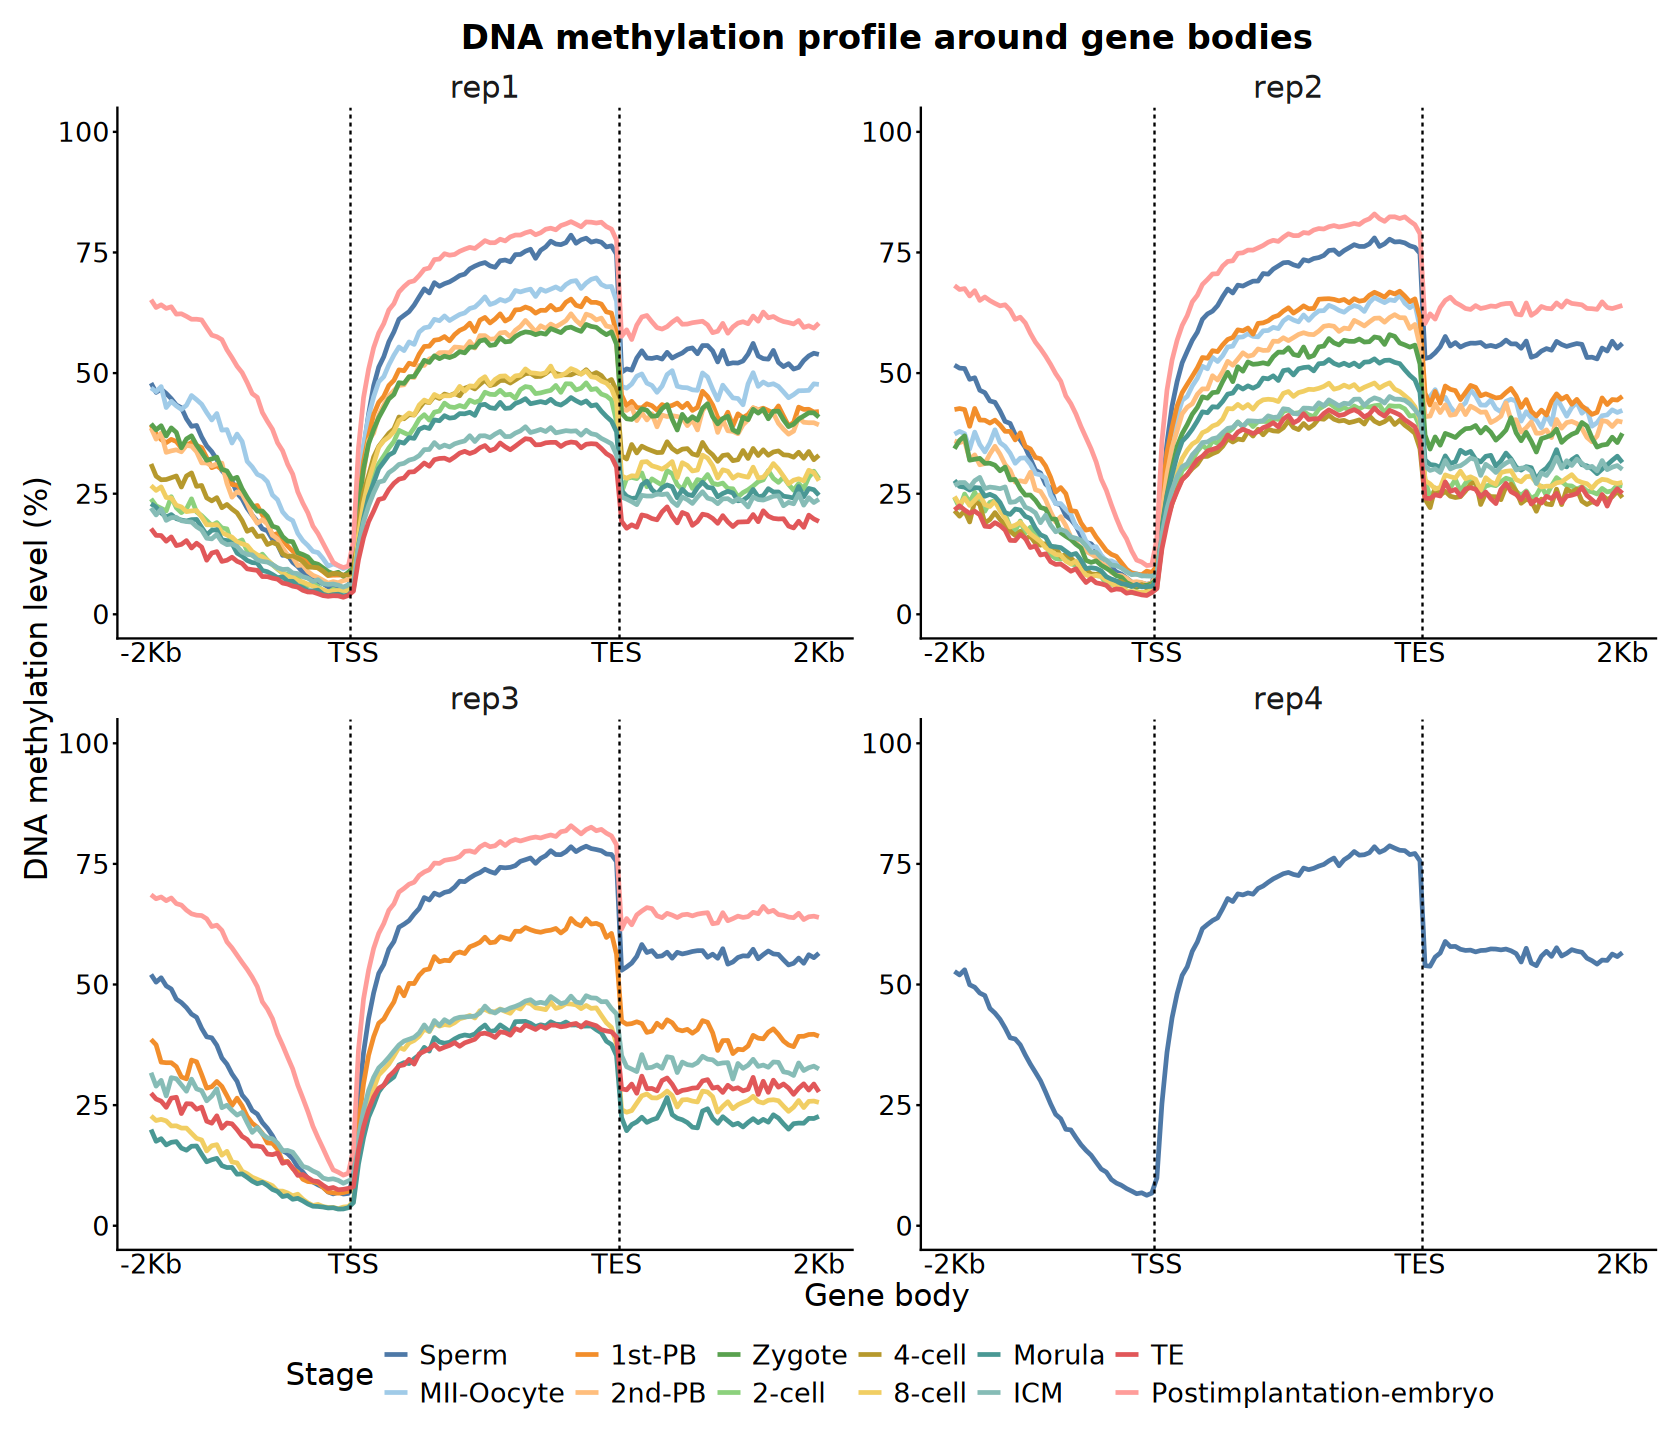

In [19]:
options(repr.plot.width = 14, repr.plot.height = 12)

ggplot(plot_df, aes(x = pos, y = meth * 100, color = Stage, group = Stage)) +
    geom_line(linewidth = 1, alpha = 1, na.rm = TRUE) +
    geom_vline(xintercept = 40.5, linetype = 2) +
    geom_vline(xintercept = 93.5, linetype = 2) +
    facet_wrap( ~ Replicate, scales = "free", ncol = 2) +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), expand = c(0.05, 0.05),
        labels = c("u1" = "-2Kb", "t1" = "TSS", "t53" = "TES", "d40" = "2Kb")) +
    coord_cartesian(ylim = c(0, 100)) +
    # scale_color_viridis_d(option = "turbo") +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around gene bodies", 
        x = "Gene body", y = "DNA methylation level (%)", 
        color = "Stage") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        strip.text = element_text(size = 18), 
        strip.background = element_blank(), 
        strip.placement = "outside", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

### b). CGI

In [20]:
# ~ 15 min
cgi_mat_List <- lapply(
    meth_list, normalizeToMatrix, CGI, value_column = "meth",
    extend = 4000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.3, background = NA, smooth = FALSE)

In [21]:
position_index <- c(
    paste0("u", seq_len(80)), 
    paste0("t", seq_len(69)), 
    paste0("d", seq_len(80))
)

plot_df <- cgi_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(
        pos = factor(pos, levels = position_index), 
        sample = factor(sample, levels = names(meth_list)))

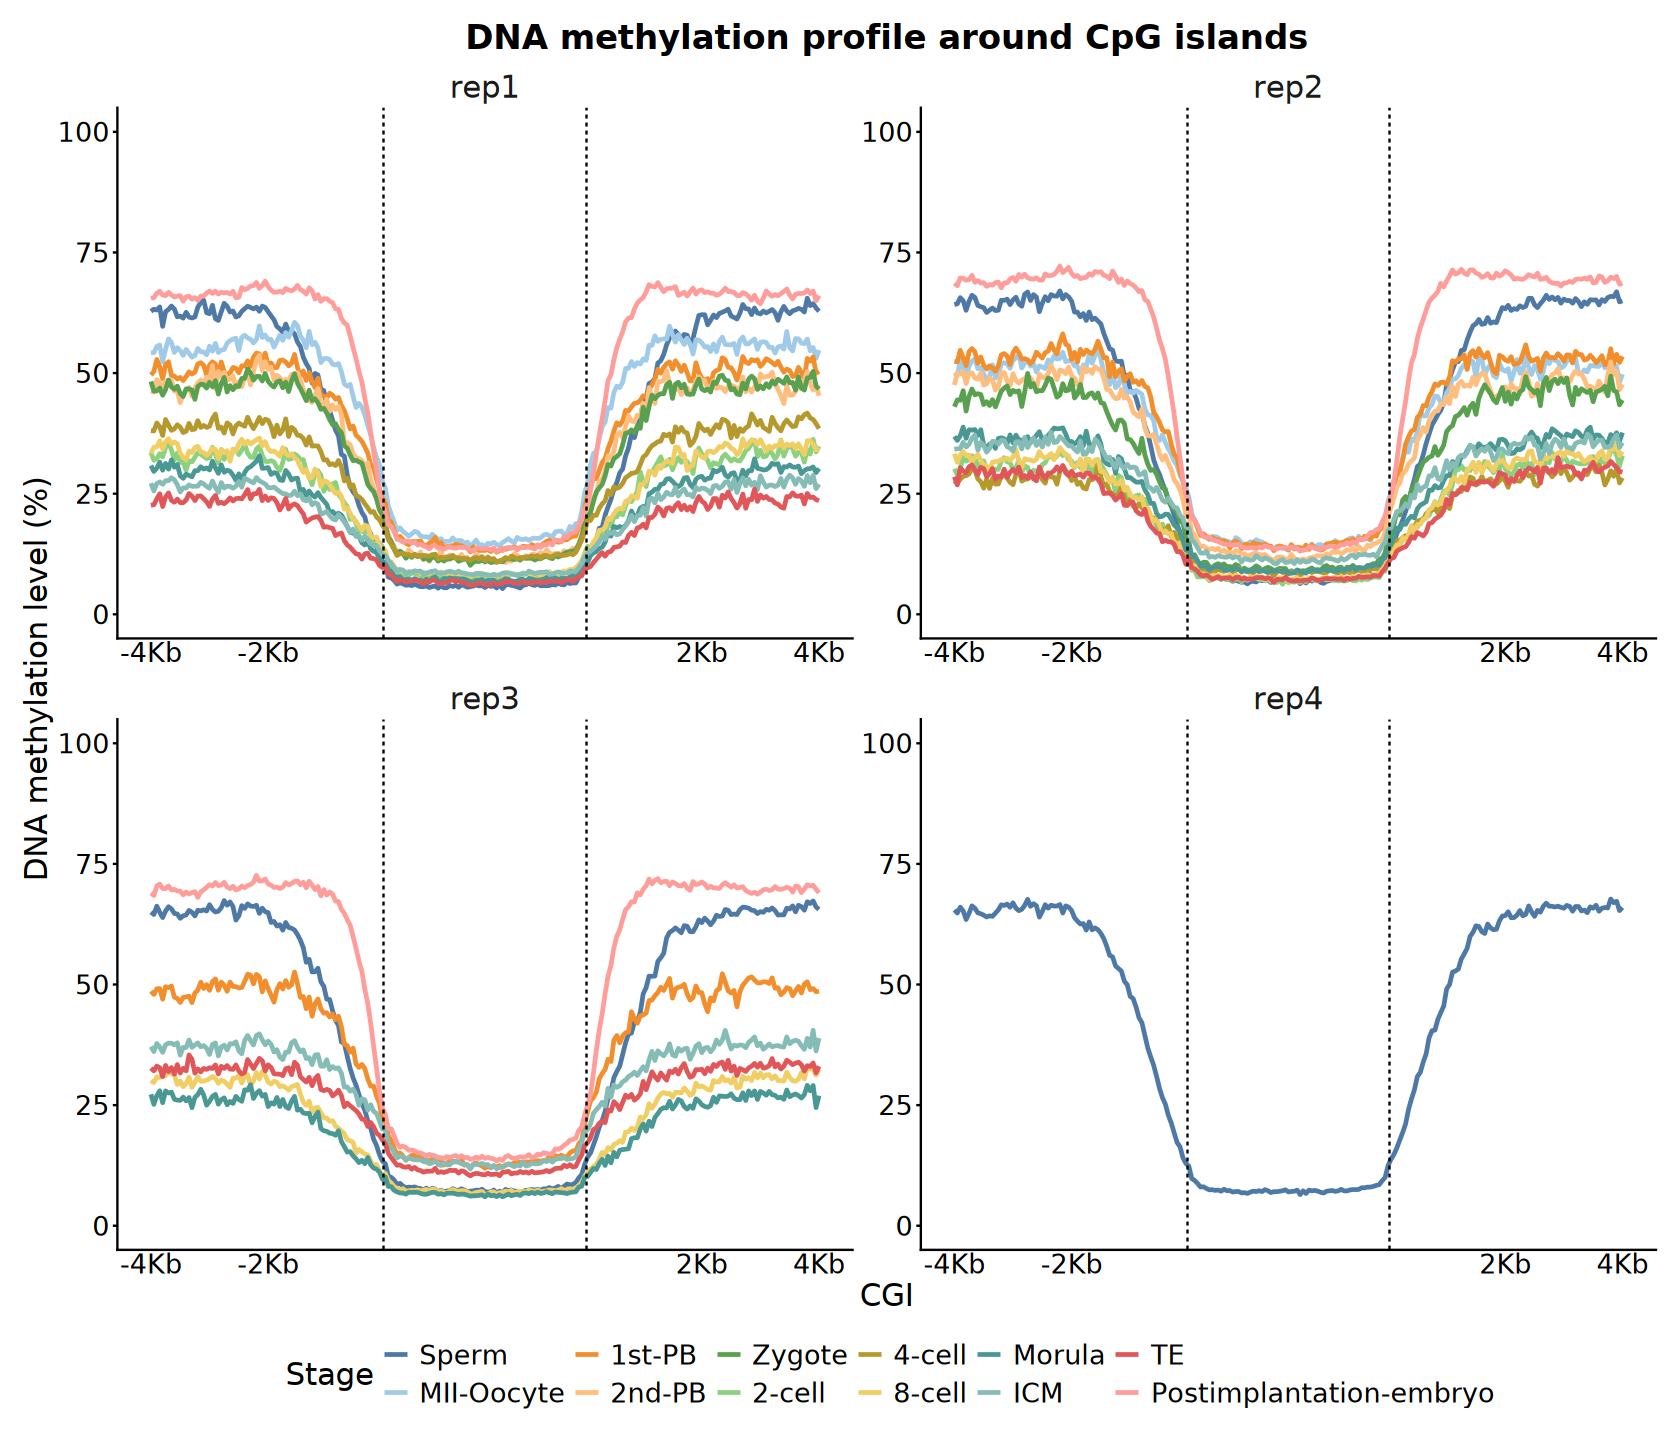

In [22]:
options(repr.plot.width = 14, repr.plot.height = 12)

ggplot(plot_df, aes(x = pos, y = meth * 100, color = Stage, group = Stage)) +
    geom_line(linewidth = 1, alpha = 1, na.rm = TRUE) +
    geom_vline(xintercept = 80.5, linetype = 2) +
    geom_vline(xintercept = 149.5, linetype = 2) +
    facet_wrap( ~ Replicate, scales = "free", ncol = 2) +
    scale_x_discrete(
        breaks = c("u1", "u41", "d40", "d80"), 
        labels = c(
            "u1" = "-4Kb", "u41" = "-2Kb", "d40" = "2Kb", "d80" = "4Kb"),
        expand = c(0.05, 0.05)) +
    coord_cartesian(ylim = c(0, 100)) +
    # scale_color_viridis_d(option = "turbo") +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around CpG islands",
        x = "CGI", y = "DNA methylation level (%)", 
        color = "Stage") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        strip.text = element_text(size = 18), 
        strip.background = element_blank(), 
        strip.placement = "outside", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

# * Reference